<h1>Практическая работа: "Бинарная логистическая регрессия"</h1>

__Задача бинарной классификации__

___Некая фирма провела анализ зависимости расхода денежных средств на рекламу и эффекта от нее. Если эффект присутствовал, 
то в датасете ставилась 1, в противном случае - 0. Результаты были представоены в виде двух DataFrame х и y.<br>
Произыести бинарную классификацию с использованием логистической регрессии.___  

In [1]:
#Загрузим необходимые библиотеки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
#Исходные данные: x - расходы на рекламу, Y - объемы продаж
x = pd.DataFrame(np.array([39, 36, 60, 21, 27, 12, 51, 57, 54, 42, 18, 9, 48, 66, 6, 30, 24, 33, 15, 21, 100, 200]))
Y = pd.DataFrame(np.array([1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1]))
#display(x, Y)

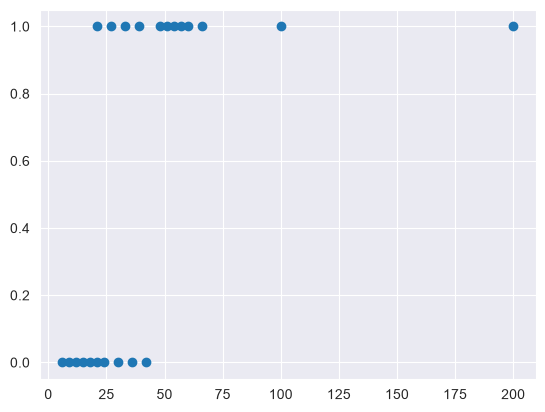

In [3]:
plt.scatter(x,Y)

_Попробуем разделить эти точки прямой линией, отделяющей один класс от другого. 
Модель начинает плохо работать в случае добавления новых точек на больших значениях x:_

In [4]:
a1 = ((x-x.mean())*(Y-Y.mean())).mean()/((x-x.mean())**2).mean()
a0 = Y.mean() - a1*x.mean()
print("Y = ", a0, " + ", a1, " * x")
x_space = np.linspace(6,70,20)
Y_pred = a0.item() + a1.item()*x_space

Y =  0    0.266493
dtype: float64  +  0    0.006333
dtype: float64  * x


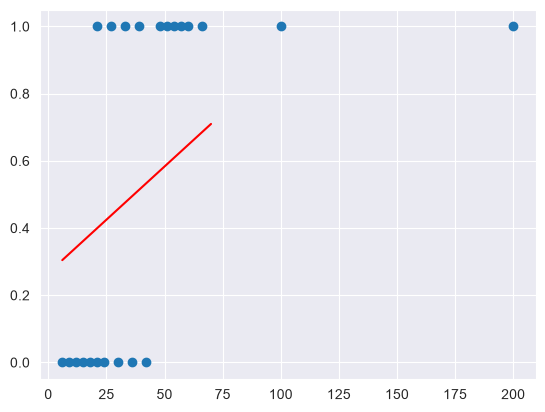

In [5]:
plt.plot(x_space, Y_pred, 'r')
plt.scatter(x, Y)

<h2>Функция логистической регрессии</h2>

__Сигмоида__

Возможное решение упомянутых выше сложностей — пропустить значение линейной регрессии через сигмоиду (sigmoid function), 
которая при любом значении x не выйдет из необходимого нам диапазона от 0 до 1. <br>
<h3>$g(x) = \frac{1}{1+ e^{-x}}$</h3>

 <img src='images/ris1.png' width=320, heigth=240>

<h3>Logistic loss или функция кросс-энтропии</h3>

В модели логистической регрессии мы не можем использовать MSE. Дело в том, 
что если мы поместим результат сигмоиды (представляющей собою нелинейную функцию) в MSE, 
то на выходе получим невыпуклую функцию (non-convex), глобальный минимум которой довольно сложно найти.
 <img src='images/ris2.png' width=520, heigth=240>
    Вместо MSE мы будем использовать функцию логистической ошибки, которую еще называют функцией бинарной кросс-энтропии (log loss, binary cross-entropy loss).

__График и формула функции логистической ошибки__<br>
 <img src='images/ris3.png' width=420, heigth=240>

$J(\theta)=-\frac{1}{n} \sum{y*log(h_{\theta}(x))+(1-y)*log(1-h_{\theta}(x))}$

<h3>Оценка качества модели</h3>

__Матрицa ошибок (confusion matrix)__<br>
 <img src='images/ris4.png' width=420, heigth=240><br>
Доля правильно предсказанных значений называется accuracy. Чтобы ее посчитать, мы берем те значения,
    которые предсказаны верно (TP + TN) и делим на общее количество прогнозов.<br>
    <h3>$accuracy=\frac{TP+TN}{TP+TN+FP+FN}$</h3>

<h2>Конкретизация задачи:</h2>

Реализовать класс модели логистической регрессии с использованием:

а) максимизации логарифмического правдоподобия методом градиентного подъема

б) минимизации функции потерь (кросс-энтропии) методом градиентного спуска

Сравнить результаты (время исполнения и достигнутые значения accuracy и f1) в случаях а и б при одном и том же числе шагов и скорости обучения.

In [6]:
#Реализуем цикл градиентного спуска
class LogisticRegressionGD(object):
    def __init__(self):
        self.a = np.zeros(2).reshape(1, 2)
        
    def sigmoid(self, x):
        return 1/(1 + np.exp(-x @ self.a))
    
    def predict(self, x):
        return self.sigmoid(x)
    
    def coefs(self):
        return self.a
      
    def LogLikelihood(self, x, Y):
        return (Y * np.log(self.predict(x)) + (1 - Y) * np.log(1 - self.predict(x))).sum()

    def CrossEntropy(self, x, Y):
        return (-Y * np.log(self.predict(x)) - (1 - Y) * np.log(1 - self.predict(x))).sum()
    
    def accuracy(self, x, Y):
        return ((self.predict(x) > 0.5)==Y).mean() 

    def fit(self, x, Y, alpha = 0.01, epsylon = 0.01, max_steps = 10000, Rtype = "LL"):
        self.a = np.zeros (x.shape[1]).reshape(x.shape[1],1)
        steps, errors = [], []
        step = 0
        for _ in range(max_steps):
            if Rtype == "LL":
                new_error = self.LogLikelihood(x, Y)
                dT_a = x.T @(Y - self.predict(x)) / x.shape[0]
                self.a += alpha*dT_a
            elif Rtype == "CE":
                new_error = self.CrossEntropy(x, Y)
                #display(new_error)
                dT_a = -x.T @(Y - self.predict(x)) / x.shape[0]
                self.a -= alpha*dT_a
            step += 1
            steps.append(step)
            errors.append(new_error)
            #if new_error < epsylon:
            #    break
        return steps, errors

In [7]:
x_ = x.copy()

import time

intercept = np.ones((x.shape[0], 1))
x_ = pd.DataFrame(np.concatenate((intercept, x), axis = 1))

In [8]:
start_time_CE = time.time()
regr_CE = LogisticRegressionGD()
steps_CE, errors_CE =  regr_CE.fit(x_, Y, alpha = 0.01, epsylon = 0.01, max_steps = 10000, Rtype = "CE") 

display(f"Время обучения: {time.time() - start_time_CE} сек.")

start_time_LL = time.time()
regr_LL = LogisticRegressionGD()
steps_LL, errors_LL =  regr_LL.fit(x_, Y, alpha = 0.01, epsylon = 0.01, max_steps = 10000, Rtype = "LL") 

display(f"Время обучения: {time.time() - start_time_LL} сек.")

'Время обучения: 7.239590883255005 сек.'

'Время обучения: 6.830214262008667 сек.'

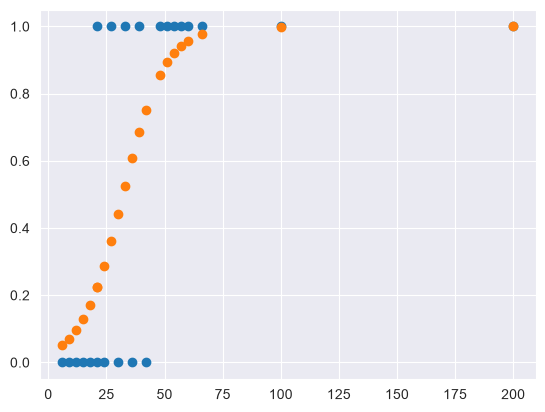

In [9]:
Y_Pred = regr_CE.predict(x_)
plt.scatter(x, Y)
plt.scatter(x, Y_Pred)

In [10]:
display(regr_CE.coefs())
#display(x_)

,0
0,-3.598875
1,0.112154


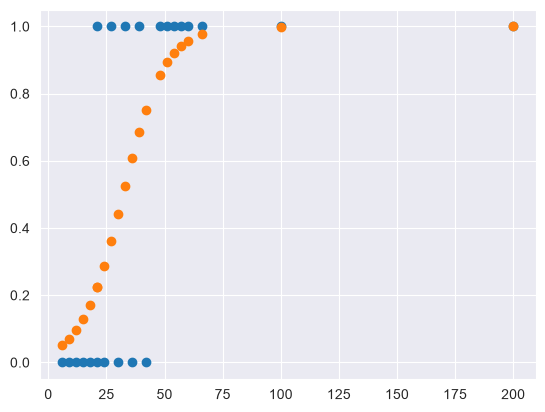

In [11]:
Y_Pred = regr_LL.predict(x_)
plt.scatter(x, Y)
plt.scatter(x, Y_Pred)

In [12]:
display(regr_LL.coefs())
#display(x_)

,0
0,-3.598875
1,0.112154


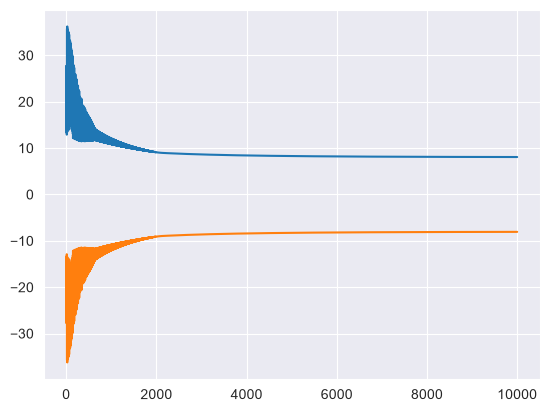

In [13]:
plt.plot(steps_CE, errors_CE)
plt.plot(steps_LL, errors_LL)

In [14]:
print(regr_CE.accuracy(x_, Y))
print(regr_LL.accuracy(x_, Y))

0    0.818182
dtype: float64
0    0.818182
dtype: float64


Реализовать расчеты способами а и б для набора данных из файла insclass_train.csv/
Для 151 406 договоров страхования транспортных средств известны значения ряда признаков, в том числе пол, возраст, стаж вождения и коэффициент бонус-малус водителя, тип, марка, модель, год выпуска, страна – производитель, мощность и объем двигателя, а также признак target, равный 1, если заключение договора с клиентом является рисковым, и 0 в противном случае (файл insclass_train.csv).

Требуется построить модель, предсказывающую значение признака target для 22 624 договоров из тестового набора данных (файл insclass_test.csv).

В обучающем наборе данных для каждого договора известны следующие поля:

variable_1 - агрегированный коэффициент бонус-малус (повышающий или понижающий стоимость полиса в зависимости от аварийности в предыдущие периоды);
variable_2 - индикатор расторжения договора по инициативе страхователя (клиента);
variable_3 - индикатор расторжения договора по инициативе страховщика (страховой компании);
variable_4 - идентификатор года выпуска транспортного средства;
variable_5 - идентификатор страны - производителя транспортного средства;
variable_6 - мощность двигателя в лошадиных силах;
variable_7 - объем двигателя в куб. см;
variable_8 - идентификатор стороны расположения руля (левый или правый);
variable_9 - пробег транспортного средства, покрываемый гарантией производителя;
variable_10 - индикатор действия гарантии на транспортное средство;
variable_11 - "мультидрайв" - индикатор допуска к управлению транспортным средством более одного водителя;
variable_12 - возраст транспортного средства (в мес.);
variable_13 - возраст водителя с максимальным стажем;
variable_14 - коэффициент возраст-стаж;
variable_15 - коэффициент краткосрочности;
variable_16 - коэффициент мощности;
variable_17 - коэффициент "мультидрайв";
variable_18 - территориальный коэффициент;
variable_19 - коэффициент "КНДР";
variable_20 - идентификатор канала продаж;
variable_21 - марка транспортного средства;
variable_22 - модель транспортного средства;
variable_23 - индикатор отечественных транспортных средств;
variable_24 - пол водителя с максимальным коэффициентом "возраст-стаж";
variable_25 - индикатор пролонгации;
variable_26 - индикатор совпадения собственника транспортного средства и водителя;
variable_27 - стаж водителя с максимальным коэффициентом "возраст-стаж";
variable_28 - тип транспортного средства;
target - класс риска, равный 1, если заключение договора с клиентом является рисковым, и 0 в противном случае.

<h2>Решение для набора данных insclass_train.csv</h2>

Файла `insclass_test.csv` с известными значениями `target` нет, поэтому для честной оценки качества разделим `insclass_train.csv` на обучающую (70%) и тестовую (30%) выборки со стратификацией по `target`.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

df = pd.read_csv('insclass_train.csv')
print(df.shape)
df.head()

(151406, 29)


,variable_1,variable_2,variable_3,variable_4,variable_5,variable_6,variable_7,variable_8,variable_9,variable_10,...,variable_20,variable_21,variable_22,variable_23,variable_24,variable_25,variable_26,variable_27,variable_28,target
0,w200,0,0,14,q2,98.0,NaN,0.0,NaN,0,...,C,j2,h45,0,0.0,0,1,19.323463,t1,0
1,w160,0,0,7,q11,106.0,NaN,0.0,NaN,0,...,C,j33,h234,0,1.0,0,1,41.177900,t1,0
2,w200,0,0,4,q3,123.0,NaN,0.0,NaN,0,...,B,j12,h28,0,0.0,0,1,3.614395,t1,0
3,w200,0,0,9,q3,102.0,NaN,0.0,NaN,0,...,C,j12,h64,0,1.0,0,0,49.041674,t1,0
4,w200,0,0,18,q20,117.0,NaN,0.0,NaN,0,...,C,j111,h991,0,1.0,0,0,17.909612,t1,0


In [16]:
# Доля рисковых договоров и доля пропусков по признакам
display(df['target'].value_counts(normalize=True).rename('доля'))
na = df.isna().mean()
display(na[na > 0].sort_values(ascending=False).rename('доля пропусков').to_frame().T.round(3))
display(df.select_dtypes('object').nunique().rename('число категорий').to_frame().T)

target
0    0.904502
1    0.095498
Name: доля, dtype: float64

,variable_15,variable_9,variable_7,variable_8,variable_14,variable_24,variable_27,variable_13,variable_12,variable_6,variable_16,variable_17,variable_18,variable_20
доля пропусков,1.0,0.888,0.632,0.197,0.019,0.015,0.014,0.011,0.01,0.001,0.0,0.0,0.0,0.0


,variable_1,variable_5,variable_20,variable_21,variable_22,variable_28
число категорий,15,39,3,192,1475,5


__Предобработка__

* Классы несбалансированы: рисковых договоров (`target = 1`) всего ≈ 9.5%.
* Удаляем признаки, которые не несут полезной информации или почти целиком состоят из пропусков:
  `variable_15` (100% пропусков), `variable_9` (89% пропусков и аномальные значения до $10^{36}$), `variable_7` (63% пропусков), `variable_3` (константа), `variable_22` (модель ТС — 1475 категорий).
* У марки ТС (`variable_21`) оставляем 20 самых частых значений, остальные объединяем в `other`.
* Категориальные признаки (`variable_1, 5, 20, 21, 28`) кодируем one-hot.
* Пропуски в числовых признаках заполняем медианой, выбросы обрезаем по 1% и 99% квантилям, затем стандартизируем.
  Все статистики (медианы, квантили, среднее, СКО) считаются только по обучающей выборке.
* Добавляем столбец из единиц для свободного члена (как `intercept` выше).

In [17]:
drop_cols = ['variable_3', 'variable_7', 'variable_9', 'variable_15', 'variable_22']
cat_cols = ['variable_1', 'variable_5', 'variable_20', 'variable_21', 'variable_28']

data = df.drop(columns=drop_cols)
top_brands = data['variable_21'].value_counts().index[:20]
data['variable_21'] = data['variable_21'].where(data['variable_21'].isin(top_brands), 'other')

y_all = data.pop('target').values
num_cols = [c for c in data.columns if c not in cat_cols]

X_train_df, X_test_df, y_train, y_test = train_test_split(
    data, y_all, test_size=0.3, stratify=y_all, random_state=42)

# статистики только по обучающей выборке
medians = X_train_df[num_cols].median()
q_low, q_high = X_train_df[num_cols].quantile(0.01), X_train_df[num_cols].quantile(0.99)
X_num_train = X_train_df[num_cols].fillna(medians).clip(q_low, q_high, axis=1)
mu, sd = X_num_train.mean(), X_num_train.std().replace(0, 1)
dummy_cols = pd.get_dummies(X_train_df[cat_cols]).columns

def prepare(X):
    X_num = (X[num_cols].fillna(medians).clip(q_low, q_high, axis=1) - mu) / sd
    X_cat = pd.get_dummies(X[cat_cols]).reindex(columns=dummy_cols, fill_value=0)
    return np.hstack([np.ones((len(X), 1)), X_num.values, X_cat.values.astype(float)])

X_train, X_test = prepare(X_train_df), prepare(X_test_df)
print('Обучающая выборка:', X_train.shape, ' тестовая выборка:', X_test.shape)
print('Доля target=1 в обучении: %.4f, в тесте: %.4f' % (y_train.mean(), y_test.mean()))

Обучающая выборка: (105984, 101)  тестовая выборка: (45422, 101)
Доля target=1 в обучении: 0.0955, в тесте: 0.0955


<h3>Класс модели</h3>

Класс `LogisticRegressionGD` выше работает с `DataFrame` и на каждом шаге несколько раз пересчитывает сигмоиду, поэтому для 106 тыс. объектов он слишком медленный. Ниже — тот же алгоритм на массивах `numpy`, дополненный расчётом f1:

а) `Rtype = "LL"` — __максимизация логарифмического правдоподобия градиентным подъёмом__:
$\quad l(a) = \frac{1}{n}\sum y\log h_a(x) + (1-y)\log(1-h_a(x)),\qquad a \leftarrow a + \alpha\,\frac{1}{n}X^T(y - h_a(X))$

б) `Rtype = "CE"` — __минимизация кросс-энтропии градиентным спуском__:
$\quad J(a) = -\frac{1}{n}\sum y\log h_a(x) + (1-y)\log(1-h_a(x)),\qquad a \leftarrow a - \alpha\,\frac{1}{n}X^T(h_a(X) - y)$

In [18]:
class LogisticRegressionBinary(object):
    def __init__(self):
        self.a = None

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def predict_proba(self, x):
        return self.sigmoid(x @ self.a).ravel()

    def predict(self, x, threshold=0.5):
        return (self.predict_proba(x) >= threshold).astype(int)

    def coefs(self):
        return self.a

    @staticmethod
    def _clip(p):
        # защита от log(0)
        return np.clip(p, 1e-12, 1 - 1e-12)

    def LogLikelihood(self, p, Y):
        p = self._clip(p)
        return (Y * np.log(p) + (1 - Y) * np.log(1 - p)).mean()

    def CrossEntropy(self, p, Y):
        p = self._clip(p)
        return (-Y * np.log(p) - (1 - Y) * np.log(1 - p)).mean()

    def accuracy(self, x, Y, threshold=0.5):
        return (self.predict(x, threshold) == Y).mean()

    def f1(self, x, Y, threshold=0.5):
        Y_pred = self.predict(x, threshold)
        tp = ((Y_pred == 1) & (Y == 1)).sum()
        fp = ((Y_pred == 1) & (Y == 0)).sum()
        fn = ((Y_pred == 0) & (Y == 1)).sum()
        return 2 * tp / (2 * tp + fp + fn) if tp > 0 else 0.0

    def fit(self, x, Y, alpha=0.1, max_steps=1000, Rtype="LL"):
        Y = Y.reshape(-1, 1)
        n = x.shape[0]
        self.a = np.zeros((x.shape[1], 1))
        steps, errors = [], []
        for step in range(1, max_steps + 1):
            p = self.sigmoid(x @ self.a)
            if Rtype == "LL":
                errors.append(self.LogLikelihood(p, Y))
                dT_a = x.T @ (Y - p) / n          # градиент лог-правдоподобия
                self.a += alpha * dT_a            # шаг подъёма
            elif Rtype == "CE":
                errors.append(self.CrossEntropy(p, Y))
                dT_a = x.T @ (p - Y) / n          # градиент кросс-энтропии
                self.a -= alpha * dT_a            # шаг спуска
            else:
                raise ValueError('Rtype должен быть "LL" или "CE"')
            steps.append(step)
        return steps, errors

<h3>Обучение способами а и б при одинаковых параметрах</h3>

Число шагов и скорость обучения одинаковы для обоих способов. Чтобы уменьшить влияние случайных колебаний нагрузки, каждое обучение повторяется 3 раза и берётся медианное время.

In [19]:
ALPHA, STEPS, REPEATS = 0.5, 3000, 3

def train(Rtype):
    times = []
    for _ in range(REPEATS):
        model = LogisticRegressionBinary()
        start = time.perf_counter()
        steps, errors = model.fit(X_train, y_train, alpha=ALPHA, max_steps=STEPS, Rtype=Rtype)
        times.append(time.perf_counter() - start)
    return model, steps, errors, np.median(times)

regr_LL_ins, steps_LL_ins, errors_LL_ins, time_LL = train("LL")
regr_CE_ins, steps_CE_ins, errors_CE_ins, time_CE = train("CE")

print(f"а) LL, градиентный подъём: {time_LL:.2f} сек.")
print(f"б) CE, градиентный спуск:  {time_CE:.2f} сек.")

а) LL, градиентный подъём: 11.62 сек.
б) CE, градиентный спуск:  9.22 сек.


In [20]:
def report(models, threshold=0.5):
    rows = {}
    for name, m in models.items():
        rows[name] = {
            'accuracy (train)': m.accuracy(X_train, y_train, threshold),
            'f1 (train)': m.f1(X_train, y_train, threshold),
            'accuracy (test)': m.accuracy(X_test, y_test, threshold),
            'f1 (test)': m.f1(X_test, y_test, threshold),
        }
    return pd.DataFrame(rows).T

res = report({'а) LL, подъём': regr_LL_ins, 'б) CE, спуск': regr_CE_ins})
res.insert(0, 'время, сек', [time_LL, time_CE])
res.insert(1, 'итог. функционал', [errors_LL_ins[-1], errors_CE_ins[-1]])
display(res.round(4))

print('Максимальное различие коэффициентов а) и б):',
      np.abs(regr_LL_ins.coefs() - regr_CE_ins.coefs()).max())
print('Доля класса 0 в тесте (accuracy константной модели):', round(1 - y_test.mean(), 4))

,"время, сек",итог. функционал,accuracy (train),f1 (train),accuracy (test),f1 (test)
"а) LL, подъём",11.6220,-0.2889,0.9116,0.2104,0.9115,0.2062
"б) CE, спуск",9.2201,0.2889,0.9116,0.2104,0.9115,0.2062


Максимальное различие коэффициентов а) и б): 0.0
Доля класса 0 в тесте (accuracy константной модели): 0.9045


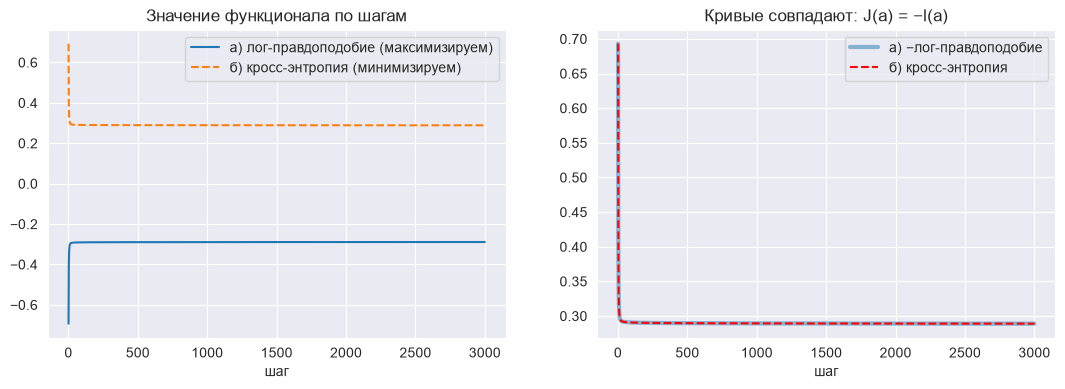

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(steps_LL_ins, errors_LL_ins, label='а) лог-правдоподобие (максимизируем)')
ax[0].plot(steps_CE_ins, errors_CE_ins, '--', label='б) кросс-энтропия (минимизируем)')
ax[0].set_xlabel('шаг'); ax[0].set_title('Значение функционала по шагам'); ax[0].legend()
ax[1].plot(steps_LL_ins, -np.array(errors_LL_ins), label='а) −лог-правдоподобие', lw=3, alpha=0.5)
ax[1].plot(steps_CE_ins, errors_CE_ins, 'r--', label='б) кросс-энтропия')
ax[1].set_xlabel('шаг'); ax[1].set_title('Кривые совпадают: J(a) = −l(a)'); ax[1].legend()
plt.show()

<h3>Выбор порога классификации</h3>

Из-за дисбаланса классов при пороге 0.5 модель редко предсказывает класс 1, и f1 получается низким, а accuracy лишь немного выше, чем у константной модели «всегда 0». Подберём порог, максимизирующий f1 на __обучающей__ выборке, и проверим его на тестовой.

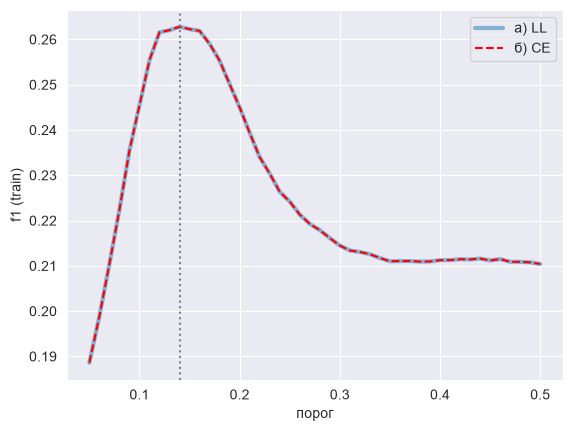

Лучший порог: 0.14


,accuracy (train),f1 (train),accuracy (test),f1 (test)
"а) LL, подъём",0.8562,0.2628,0.8543,0.2529
"б) CE, спуск",0.8562,0.2628,0.8543,0.2529


In [22]:
thresholds = np.arange(0.05, 0.51, 0.01)
f1_by_thr = {name: [m.f1(X_train, y_train, t) for t in thresholds]
             for name, m in {'а) LL': regr_LL_ins, 'б) CE': regr_CE_ins}.items()}
best_thr = thresholds[np.argmax(f1_by_thr['а) LL'])]

plt.plot(thresholds, f1_by_thr['а) LL'], lw=3, alpha=0.5, label='а) LL')
plt.plot(thresholds, f1_by_thr['б) CE'], 'r--', label='б) CE')
plt.axvline(best_thr, color='gray', ls=':')
plt.xlabel('порог'); plt.ylabel('f1 (train)'); plt.legend(); plt.show()

print('Лучший порог:', round(best_thr, 2))
display(report({'а) LL, подъём': regr_LL_ins, 'б) CE, спуск': regr_CE_ins}, best_thr).round(4))

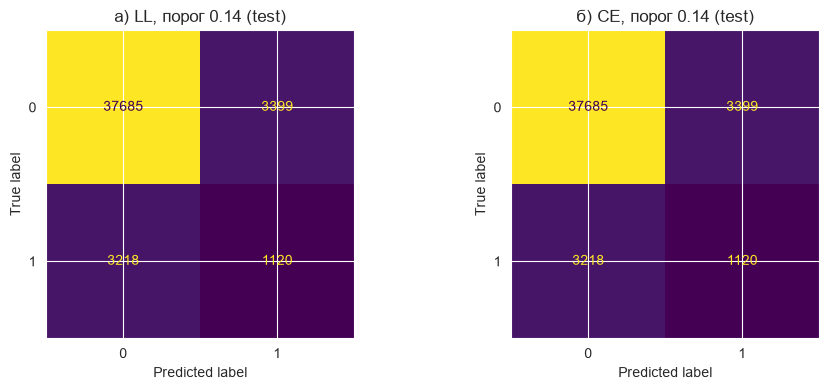

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for axis, (name, m) in zip(ax, {'а) LL': regr_LL_ins, 'б) CE': regr_CE_ins}.items()):
    cm = confusion_matrix(y_test, m.predict(X_test, best_thr))
    ConfusionMatrixDisplay(cm).plot(ax=axis, colorbar=False)
    axis.set_title(f'{name}, порог {best_thr:.2f} (test)')
plt.show()

<h3>Сравнение при разных скоростях обучения и числе шагов</h3>

In [24]:
rows = []
for alpha in [0.01, 0.1, 0.5]:
    for n_steps in [300, 1000]:
        for Rtype in ['LL', 'CE']:
            m = LogisticRegressionBinary()
            start = time.perf_counter()
            m.fit(X_train, y_train, alpha=alpha, max_steps=n_steps, Rtype=Rtype)
            rows.append({'alpha': alpha, 'шагов': n_steps, 'способ': Rtype,
                         'время, сек': time.perf_counter() - start,
                         'accuracy (test)': m.accuracy(X_test, y_test),
                         'f1 (test, порог 0.5)': m.f1(X_test, y_test),
                         f'f1 (test, порог {best_thr:.2f})': m.f1(X_test, y_test, best_thr)})
grid = pd.DataFrame(rows).set_index(['alpha', 'шагов', 'способ'])
display(grid.round(4))

время, сек  accuracy (test)  f1 (test, порог 0.5)  \
alpha шагов способ                                                      
0.01  300   LL          1.0254           0.9090                0.1702   
            CE          0.9291           0.9090                0.1702   
      1000  LL          3.0760           0.9106                0.2070   
            CE          3.0255           0.9106                0.2070   
0.10  300   LL          0.8785           0.9112                0.2065   
            CE          0.8795           0.9112                0.2065   
      1000  LL          2.9708           0.9113                0.2064   
            CE          3.3180           0.9113                0.2064   
0.50  300   LL          1.1075           0.9114                0.2066   
            CE          0.9605           0.9114                0.2066   
      1000  LL          3.4048           0.9114                0.2067   
            CE          3.4042           0.9114                0.2067   

                    f1 (test, порог 0.14)  
alpha шагов способ                         
0.01  300   LL                     0.1881  
            CE                     0.1881  
      1000  LL                     0.2396  
            CE                     0.2396  
0.10  300   LL                     0.2472  
            CE                     0.2472  
      1000  LL                     0.2494  
            CE                     0.2494  
0.50  300   LL                     0.2515  
            CE                     0.2515  
      1000  LL                     0.2534  
            CE                     0.2534

__Проверка: сравнение с `LogisticRegression` из scikit-learn__

In [25]:
from sklearn.linear_model import LogisticRegression

start = time.perf_counter()
sk = LogisticRegression(max_iter=5000, fit_intercept=False).fit(X_train, y_train)
sk_time = time.perf_counter() - start
sk_proba = sk.predict_proba(X_test)[:, 1]

def f1_np(y_true, y_pred):
    tp = ((y_pred == 1) & (y_true == 1)).sum()
    return 2 * tp / (2 * tp + ((y_pred == 1) & (y_true == 0)).sum() + ((y_pred == 0) & (y_true == 1)).sum())

print(f'sklearn: время {sk_time:.2f} сек, accuracy {((sk_proba >= 0.5) == y_test).mean():.4f}, '
      f'f1 (0.5) {f1_np(y_test, (sk_proba >= 0.5).astype(int)):.4f}, '
      f'f1 ({best_thr:.2f}) {f1_np(y_test, (sk_proba >= best_thr).astype(int)):.4f}')

sklearn: время 0.48 сек, accuracy 0.9114, f1 (0.5) 0.2045, f1 (0.14) 0.2556


<h2>Выводы</h2>

1. __Результаты способов а и б совпадают.__ При одинаковых скорости обучения ($\alpha = 0.5$) и числе шагов (3000) обе модели получили одни и те же коэффициенты (максимальное различие — 0.0), одинаковые accuracy и f1 на обучающей и тестовой выборках. Причина в том, что кросс-энтропия — это лог-правдоподобие с обратным знаком: $J(a) = -l(a)$, поэтому $\nabla J = -\nabla l$, и шаг спуска $a - \alpha\nabla J$ в точности равен шагу подъёма $a + \alpha\nabla l$. Кривые обучения тоже зеркальны: лог-правдоподобие растёт до −0.289, кросс-энтропия падает до 0.289.

2. __Время исполнения практически одинаковое__ (≈ 8.4 сек на 3000 шагов для обоих способов; в таблице с разными $\alpha$ и числом шагов разница — в пределах нескольких процентов и меняет знак от запуска к запуску). Вычислительная сложность шага одинакова, различия объясняются только случайными колебаниями нагрузки на компьютер.

3. __Качество модели на тестовой выборке__ (порог 0.5): accuracy = 0.9115, f1 = 0.206. Accuracy здесь малоинформативна: константная модель «всегда 0» даёт 0.9045, т.к. рисковых договоров всего 9.5%. Подбор порога по обучающей выборке (0.14) повышает f1 на тесте до 0.253 ценой снижения accuracy до 0.854 — модель находит больше рисковых договоров, но и чаще ошибается на нерисковых.

4. Скорость обучения влияет на оба способа одинаково: при $\alpha = 0.01$ за 300 шагов модель не успевает сойтись (f1 = 0.170 / 0.188), при $\alpha = 0.5$ уже 300 шагов дают результат, близкий к итоговому.

5. Реализованная модель даёт практически тот же результат, что и `LogisticRegression` из scikit-learn (accuracy 0.9114, f1 0.205 / 0.256), но обучается дольше, т.к. использует простой градиентный метод вместо квазиньютоновского L-BFGS.

Итог: для логистической регрессии максимизация логарифмического правдоподобия градиентным подъёмом и минимизация кросс-энтропии градиентным спуском — одна и та же задача оптимизации, записанная с разным знаком, поэтому при одинаковых параметрах они дают одинаковые время и качество. Низкое значение f1 связано не со способом обучения, а с дисбалансом классов и ограниченной разделяющей способностью линейной модели на этих признаках.